# Reproduce the manuscript results

Aggregate tables and figures from **Compiling Operational Knowledge for Dynamic Assortment: LLM-Guided Policy Learning under Resource Constraints**. Numbering follows the RQ1–RQ3 manuscript (`main_1113.tex`). [Browse the CSV index](results/README.md). Figures based on a calculation use the manuscript's displayed means.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from scripts.reproduce_results import read_csv, render_figure, table_html

## Main tables

### Table 1. Structural comparison of the two dynamic assortment regimes

[CSV](results/table-01.csv) · Reported in manuscript

In [2]:
display(HTML(table_html(read_csv("table-01.csv"))))

Operational dimension,Expedia: Hotel inventory regime,KuaiSearch: Product exposure regime
Arrival context $x_t$,Customer hotel-search request,E-commerce search query
Candidate pool $C_t$,Fixed catalog or destination properties,Query-retrieved candidate products
Scarce resource $r_{tj}$,Remaining room inventory $q_{tj}$,Remaining impression budget $b_{tj}$
Depletion law,"Stochastic on purchase: $q_{t+1,j} = q_{tj} - \ind\{Y_t = j\}$","Deterministic on display: $b_{t+1,j} = b_{tj} - \ind\{j \in A_t\}$"
Per-request consumption,At most $1$ unit across all $j \in A_t$,Exactly $|A_t|$ units (one per displayed item)
Opportunity-cost weight,"Choice-weighted: $P_t(j \mid A_t, x_t)\mu_{tj}$",Unconditional per slot: $\mu_{tj}$ for each $j \in A_t$


### Table 2. Empirical populations, temporal data splits, and demand-support scenarios across the nine operating settings

[CSV](results/table-02.csv) · Reported in manuscript

In [3]:
display(HTML(table_html(read_csv("table-02.csv"))))

Setting,Population definition and support rule,Train,Validation,Test,Total
Days,Chronological daily episodes,140,20,51,211
Requests,Customer arrivals within days,16796,2417,6159,25372
Setting,Population definition and support rule,Train,Validation,Test,Total
All groups (sum),Aggregate across the three market tiers,211714,45488,46632,303834
Head,206 markets; training searches n_m ≥ 200,96793,20752,20856,138401
Regular,813 markets; training searches 50 ≤ n_m ≤ 199,77849,16747,17144,111740
Cold,"1,225 markets; training searches 20 ≤ n_m ≤ 49",37072,7989,8632,53693
Setting,Population definition and support rule,Train,Validation,Test,Total
Overall,Mixed-query episodes across all 44 clusters,299200,75081,10111,384392
Q-Head,Frequent queries; n_q ≥ 50,40431,9409,1458,51298


### Table 3. Out-of-sample operating performance across booking-depleted hotel inventory and display-depleted product exposure

[CSV](results/table-03.csv) · Reported in manuscript

Expedia30 reports daily booking revenue. Head, Regular, and Cold report revenue per search. KuaiSearch reports expected GMV per 1,000 requests with prices divided by 100. SD is the reported standard deviation.

In [4]:
display(HTML(table_html(read_csv("table-03.csv"))))

Section,Method,30 Hotels revenue/day Mean,30 Hotels revenue/day SD,Head revenue/search Mean,Head revenue/search SD,Regular revenue/search Mean,Regular revenue/search SD,Cold revenue/search Mean,Cold revenue/search SD
Operating-rule and slate-decomposition benchmarks,LoggedTopK,5905.22,0.52,81.97,0.89,82.34,0.35,78.97,0.71
Operating-rule and slate-decomposition benchmarks,Random,4125.10,0.24,60.00,0.15,69.79,0.62,54.98,1.09
Operating-rule and slate-decomposition benchmarks,Myopic,5506.02,0.32,90.80,0.31,95.56,0.54,88.53,0.68
Operating-rule and slate-decomposition benchmarks,SlateQ Greedy,6105.06,0.19,85.10,0.46,81.03,0.34,79.88,0.98
Operating-rule and slate-decomposition benchmarks,SlateQ TopK,6204.10,1.71,82.37,0.96,79.69,0.27,80.06,0.39
Unaugmented DRL baselines (A2C across neural backbones),A2C GRU,8100.06,38.51,92.15,2.17,87.05,1.34,78.20,9.49
Unaugmented DRL baselines (A2C across neural backbones),A2C RNN,7926.09,77.96,93.12,1.44,85.72,1.47,77.20,3.60
Unaugmented DRL baselines (A2C across neural backbones),A2C Transformer,8093.58,34.55,101.27,2.06,102.35,2.41,76.60,3.47
LLM-compiled S/R (A2C Transformer),Qwen + S/R,8320.62,50.59,118.62,0.55,117.05,0.26,95.24,0.70
LLM-compiled S/R (A2C Transformer),DeepSeek + S/R,8399.51,9.19,117.81,0.38,109.47,6.29,89.21,2.27


### Table 4. Channel ablations and representation-source comparisons on A2C Transformer across all nine settings

[CSV](results/table-04.csv) · Reported in manuscript

In [5]:
display(HTML(table_html(read_csv("table-04.csv"))))

Setting,Base Mean,Base SD,S-only Mean,S-only SD,R-only Mean,R-only SD,Human S/R Mean,Human S/R SD,Best Text Encoder Mean,Best Text Encoder SD,Full S/R (Qwen) Mean,Full S/R (Qwen) SD
30 Hotels,8093.58,34.55,8195.24,61.64,8295.63,37.10,8113.95,25.53,7953.34,49.14,8320.62,50.59
Head,101.27,2.06,112.62,1.76,111.73,1.91,112.74,0.76,113.05,1.41,118.62,0.55
Regular,102.35,2.41,108.80,1.27,112.71,0.96,110.16,0.79,114.25,1.61,117.05,0.26
Cold,76.60,3.47,86.99,2.22,90.27,3.27,86.55,0.71,90.73,4.48,95.24,0.70
Setting,Base Mean,Base SD,S-only Mean,S-only SD,R-only Mean,R-only SD,Human S/R Mean,Human S/R SD,Best Text Encoder Mean,Best Text Encoder SD,Full S/R (Qwen) Mean,Full S/R (Qwen) SD
Overall,3951.96,0.99,4155.42,8.19,4219.43,5.14,3951.61,6.34,3992.84,2.44,4350.00,40.06
Q-Head,4598.88,15.98,4629.75,16.71,4678.19,14.92,4675.38,6.71,4591.07,5.94,4894.02,16.99
Q-Regular,5708.23,18.13,5987.64,18.15,5874.13,17.19,6009.24,9.75,6107.31,20.83,6197.50,19.38
Q-Cold,3218.12,11.54,3226.35,9.24,3221.98,6.18,3517.48,5.85,3229.87,11.97,3520.41,7.21
Q-Unseen,3197.64,4.84,3219.65,6.18,3213.34,6.56,3274.57,6.10,3203.37,2.29,3492.74,7.36


### Table 5. Frozen-policy deployment synthesis: Topline expansion vs. premium dilution and peak-target capacity substitution

[CSV](results/table-05.csv) · Reported in manuscript

In [6]:
display(HTML(table_html(read_csv("table-05.csv"))))

Setting,Capacity shift,Full rev. growth (%),Gap at ref.,Gap at max,Target y_c,Min. cap. (Base / Full),Full rev. at min. cap.
Expedia30,q: 2→ 4,+33.70,+214.72,+332.80,10805.42,4 / 3,11293.77
Expedia Head,q: 1→ 4,+18.93,+17.35,+6.79,134.28,4 / 2,137.71
Expedia Regular,q: 1→ 4,+7.64,+12.76,+12.95,120.38,4 / 1,123.87
Expedia Cold,q: 1→ 4,+7.30,+6.88,+11.91,100.49,4 / 1,104.75
Setting,Capacity shift,Full rev. growth (%),Gap at ref.,Gap at max,Target y_c,Min. cap. (Base / Full),Full rev. at min. cap.
Overall,ρ: 1→ 1.5,+13.71,+367.04,+100.18,4833.86,1.50 / 1.50,4934.04
Q-Head,ρ: 1→ 1.5,+11.22,+295.14,+303.48,5139.49,1.50 / 1.50,5442.97
Q-Regular,ρ: 1→ 1.5,+27.97,+179.31,+200.62,6066.31,1.50 / 1.25,6106.50
Q-Cold,ρ: 1→ 1.5,+24.60,+23.33,+7.76,1761.38,1.50 / 1.50,1769.14
Q-Unseen,ρ: 1→ 1.5,+10.79,+100.24,+1.43,1570.64,1.50 / 1.50,1572.07


## Main figures

### Figure 1. Sequential assortment control under dual resource-depletion regimes

[CSV](results/figure-01.csv) · Conceptual figure

![Sequential assortment control under dual resource-depletion regimes](assets/background.png)

### Figure 2. Offline LLM compilation and sequential deployment framework

[CSV](results/figure-02.csv) · Conceptual figure

![Offline LLM compilation and sequential deployment framework](assets/method.png)

### Figure 3. Share of Full S/R gain captured by the stronger single interface

[CSV](results/figure-03.csv) · Table EC.9

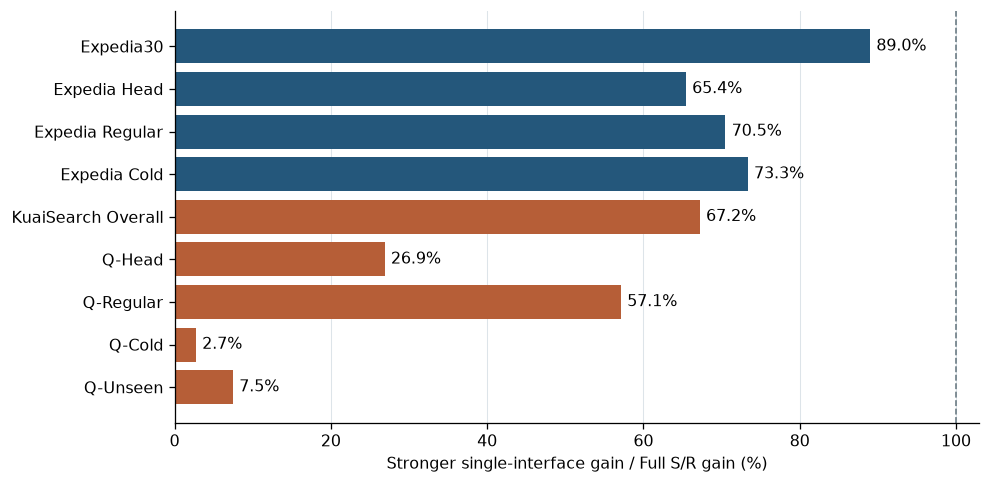

In [7]:
figure = render_figure("capture", read_csv("figure-03.csv"))
display(figure)
plt.close(figure)

### Figure 4. Retained frozen-policy uplift ranges across 41 capacity conditions

[CSV](results/figure-04.csv) · Tables EC.15 and EC.16

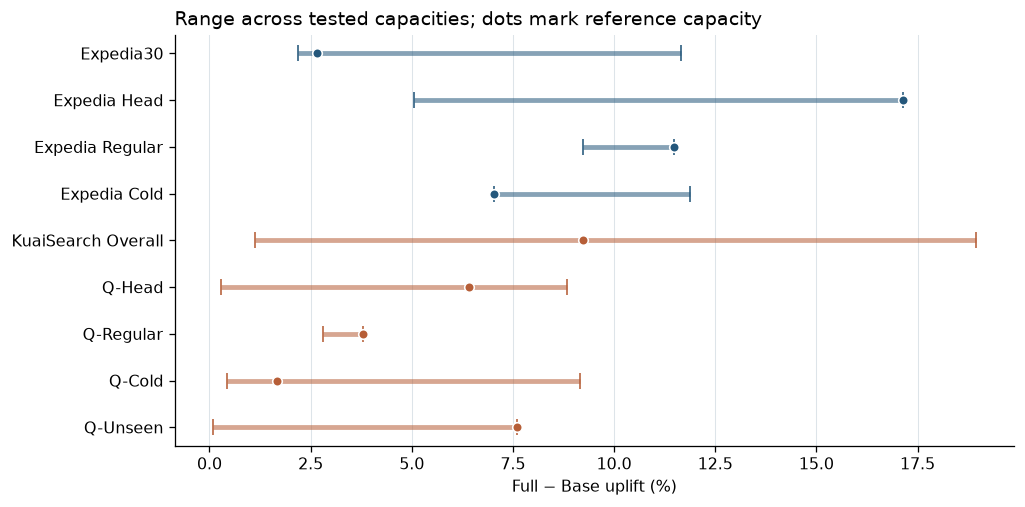

In [8]:
figure = render_figure("ranges", read_csv("figure-04.csv"))
display(figure)
plt.close(figure)

### Figure 5. Joint policy and capacity selection in Expedia30

[CSV](results/figure-05.csv) · Derived from Table EC.17 and the manuscript cost parameterization

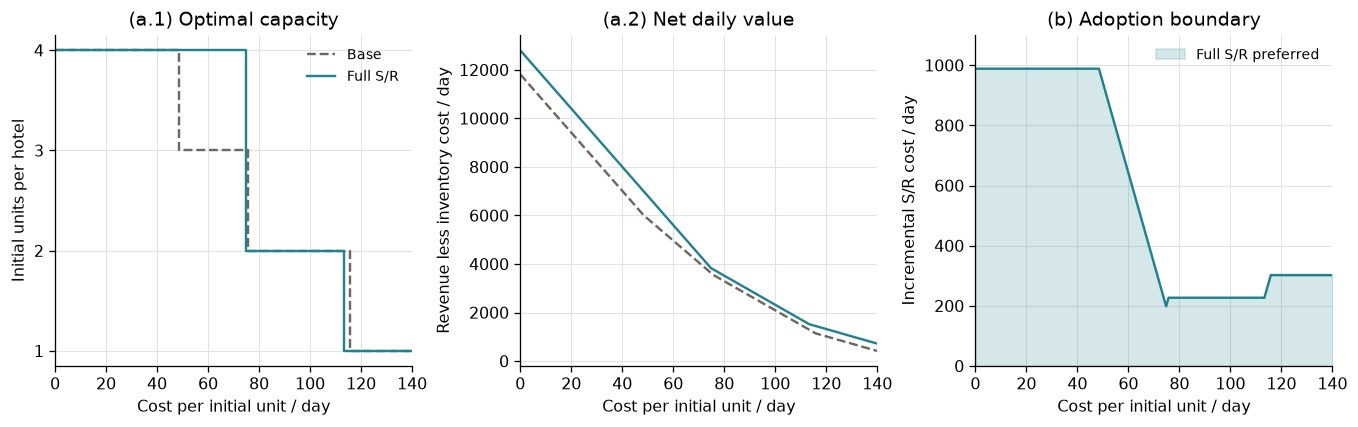

In [9]:
figure = render_figure("adoption", read_csv("figure-05.csv"))
display(figure)
plt.close(figure)

## Appendix tables

### Table EC.1. Pre-decision input schema and non-anticipative boundaries for executable S/R programs

[CSV](results/table-ec-01.csv) · Reported in manuscript

In [10]:
display(HTML(table_html(read_csv("table-ec-01.csv"))))

Input category,Representative variables,Interface role and timing boundary
Request context ($X_t$),"Customer segment, search query metadata, party attributes",Observed upon arrival prior to assortment selection
Candidate attributes ($W_t$),"Room rate or item price, star/quality ratings, 30-day item logs",Aligned with candidate indices $j \in C_t$
Resource ledger ($R_t$),Remaining room stock $q_{tj}$ or exposure ratio $\tilde{b}_{tj}$,Updated strictly by realized prior transitions
Horizon progress ($H_t$),"Elapsed fraction $1 - \tau_t$, remaining fraction $\tau_t$, remaining steps",Computed against true episode length $T_e$
Frozen summaries ($\eta$),"Training exposure frequency, smoothed conversion, support count",Estimated on training split and held fixed out of sample
Model-based primitives,"Singleton expected value $\widehat{u}_{tj}^{(1)}$, bucketed demand forecast $\widehat{D}_{tj}$",Pre-decision expectations from training-fitted models
Feasibility mask ($M_t$),"Binary indicator for $j \in V_t$ ($r_{tj} > 0$, non-padded)",Excludes exhausted and padded entries from set statistics
Realized outcomes,"Current choice $Y_t$, future arrivals $(x_{t'}, C_{t'})_{t' > t}$",Strictly withheld from $S$; $R$ accesses transitions in training only


### Table EC.2. Summary of compiled state (S^*) and reward (R^*) interface dimensions

[CSV](results/table-ec-02.csv) · Reported in manuscript

In [11]:
display(HTML(table_html(read_csv("table-ec-02.csv"))))

Operating environment,Global f_t^global,Candidate f_tj^item,Auxiliary reward R_t^aux
Expedia30 (fixed 30 hotels),8 dimensions,3 per hotel (98 total with globals),Scalar potential difference per step
"Expedia Head, Regular, Cold",8 dimensions,4 per candidate (B × M × 4),Scalar pool contrast per request
KuaiSearch (Overall & 4 Query tiers),8 dimensions,4 per candidate (B × M × 4),Scalar pool contrast per request


### Table EC.3. Compiled Global State Builder (S^*) features for Expedia30

[CSV](results/table-ec-03.csv) · Reported in manuscript

In [12]:
display(HTML(table_html(read_csv("table-ec-03.csv"))))

Feature,Operational meaning,Mathematical specification
"$f_{t,1}^{\mathrm{global}}$",Stock-to-horizon balance,$\tanh\bigl(\frac{1}{30}\sum_{j=1}^{30} \tilde{q}_{tj} - \tau_t\bigr)$
"$f_{t,2}^{\mathrm{global}}$",Segment price alignment,$\tanh\bigl(\bar{p}(x_t) - \bar{p}_t^{\mathrm{inv}}\bigr)$
"$f_{t,3}^{\mathrm{global}}$",Catalog support confidence,$\tanh\bigl(\frac{1}{30}\sum_{j=1}^{30} c_j\bigr)$
"$f_{t,4}^{\mathrm{global}}$",Stock-weighted demand pressure,Inventory-fraction-weighted average of $\pi_{tj}$ across the catalog
"$f_{t,5}^{\mathrm{global}}$",Available-catalog price level,$\tanh(\bar{p}_t^{\mathrm{inv}})\ind\{V_t \neq \emptyset\}$
"$f_{t,6}^{\mathrm{global}}$",Mean feasible demand pressure,$\tanh\bigl(\frac{1}{|V_t|}\sum_{j \in V_t} \pi_{tj}\bigr)$ for $V_t \neq \emptyset$ ($0$ otherwise)
"$f_{t,7}^{\mathrm{global}}$",Price–pressure co-movement,"$\tanh\bigl(\frac{1}{|V_t|}\sum_{j \in V_t} \Delta\tilde{p}_{tj}\,\pi_{tj}\bigr)$ for $V_t \neq \emptyset$"
"$f_{t,8}^{\mathrm{global}}$",Mean feasible price match,$\tanh\bigl(\frac{1}{|V_t|}\sum_{j \in V_t} m_{tj}\bigr)$ for $V_t \neq \emptyset$
"$f_{tj,1}^{\mathrm{item}}$",Pressure-adjusted relative price,$\tilde{q}_{tj}\tanh\bigl(\Delta\tilde{p}_{tj} - 0.25\pi_{tj}\bigr)$
"$f_{tj,2}^{\mathrm{item}}$",Horizon-adjusted match margin,$\tilde{q}_{tj}\tanh\bigl(m_{tj} - \tau_t \pi_{tj}\bigr)$


### Table EC.4. Pre-decision base global summaries (g_t,1:8^0) and item primitives supplied to heterogeneous-hotel compilation

[CSV](results/table-ec-04.csv) · Reported in manuscript

In [13]:
display(HTML(table_html(read_csv("table-ec-04.csv"))))

Primitive,Operational meaning,Construction from pre-decision state and $\eta$
"$g_{t,1}^0$",Centered remaining horizon,"$\tau_t - 0.5$, tracking remaining selling window"
"$g_{t,2}^0$",Aggregate inventory coverage,$\tanh\bigl(\log(\sum_{j \in V_t} q_{tj} / \sum_{j \in V_t} \widehat{D}_{tj})\bigr)$; negative under aggregate scarcity
"$g_{t,3}^0$",Mean stockout-pressure index,Feasible-set mean of $\sigma(\log(\widehat{D}_{tj}/q_{tj}))$ over $j \in V_t$
"$g_{t,4}^0$",Mean holding-value level,Bounded mean of $\widehat{h}_{tj}$ normalized by mean positive candidate price
"$g_{t,5}^0$",Peak current match opportunity,"Smooth-max (log-sum-exp) of $m_{tj}$ over $V_t$, adjusted for $|V_t|$"
"$g_{t,6}^0$",Current service-value dispersion,Bounded coefficient of variation of $\widetilde{v}_{tj}^{\mathrm{now}}$ across $j \in V_t$
"$g_{t,7}^0$",Within-pool substitute density,"Attribute similarity across $V_t$ over standardized price, star, review, and location"
"$g_{t,8}^0$",Market-item support depth,Mean of destination-level and property-level training support indices
$v_{tj}$,Item demand-to-stock pressure,$\tanh(\log(\widehat{D}_{tj}/q_{tj}))$
$m_{tj}$,Request–hotel match score,Centered product of log-price affordability and $\sqrt{\text{star fit} \times \text{quality}}$


### Table EC.5. Tier-specific global state recombinations (f_t^global) in validated heterogeneous-hotel S^* programs

[CSV](results/table-ec-05.csv) · Reported in manuscript

In [14]:
display(HTML(table_html(read_csv("table-ec-05.csv"))))

Market tier,Modified coordinates,"Compiled global transformations (unlisted coordinates retain $f_{t,k}^{\mathrm{global}} = g_{t,k}^0$)"
Head,"$k \in \{1, 3, 4, 6\}$","$f_{t,1}^{\mathrm{global}} = g_{t,1}^0 + 0.50 g_{t,2}^0$; $f_{t,3}^{\mathrm{global}} = g_{t,3}^0 - 0.30 g_{t,4}^0$; $f_{t,4}^{\mathrm{global}} = g_{t,4}^0 + 0.20 g_{t,5}^0$; $f_{t,6}^{\mathrm{global}} = g_{t,6}^0 + 0.10 g_{t,7}^0$."
Regular,"$k \in \{2, 3, 8\}$","$f_{t,2}^{\mathrm{global}} = g_{t,2}^0 + 0.25 g_{t,4}^0$; $f_{t,3}^{\mathrm{global}} = g_{t,3}^0 - 0.15 g_{t,1}^0$; $f_{t,8}^{\mathrm{global}} = 1.25 g_{t,8}^0$."
Cold,"$k \in \{1, 3, 4, 5, 7\}$","$f_{t,1}^{\mathrm{global}} = g_{t,1}^0 + 0.50 g_{t,2}^0$; $f_{t,3}^{\mathrm{global}} = g_{t,3}^0 - 0.30 g_{t,4}^0$; $f_{t,4}^{\mathrm{global}} = g_{t,4}^0(1.20 + 0.80 g_{t,5}^0)$; $f_{t,5}^{\mathrm{global}} = g_{t,5}^0 + 0.10 g_{t,6}^0$; $f_{t,7}^{\mathrm{global}} = g_{t,7}^0 - 0.20 f_{t,3}^{\mathrm{global}}$."


### Table EC.6. Compiled Global State Builder (S^*) features for KuaiSearch Overall

[CSV](results/table-ec-06.csv) · Reported in manuscript

In [15]:
display(HTML(table_html(read_csv("table-ec-06.csv"))))

Feature,Operational meaning,Mathematical specification (means $\bar{\cdot}_{V_t}$ taken over feasible items $j \in V_t$)
"$f_{t,1:2}^{\mathrm{global}}$",Episode timing,Elapsed fraction $1 - \tau_t$ and remaining fraction $\tau_t$
"$f_{t,3:4}^{\mathrm{global}}$",Pool price and singleton value,Mean log price $\overline{\ell^p}_{V_t}$ and mean singleton expected revenue $\overline{\widehat{u}^{(1)}}_{V_t}$
"$f_{t,5}^{\mathrm{global}}$",Mean exposure availability,Mean remaining budget ratio $\overline{\tilde{b}}_{V_t} = \frac{1}{|V_t|}\sum_{j \in V_t} \tilde{b}_{tj}$
"$f_{t,6:7}^{\mathrm{global}}$",Pool frequency and order depth,Mean $\log(1 + f_j)$ and mean $\log(1 + \text{ord}_j)$ across $j \in V_t$
"$f_{t,8}^{\mathrm{global}}$",Tight-budget candidate share,$\frac{1}{|V_t|}\sum_{j \in V_t} \ind\{\tilde{b}_{tj} < 0.50\}$
"$f_{tj,1}^{\mathrm{item}}$",Feasible-centered log price,$\tanh\bigl(\ell_{tj}^p - \overline{\ell^p}_{V_t}\bigr)$
"$f_{tj,2}^{\mathrm{item}}$",Historical order-to-display margin,$\tanh\bigl(\log(1 + \text{ord}_j) - \log(1 + \text{disp}_j)\bigr)$
"$f_{tj,3}^{\mathrm{item}}$",Horizon-weighted exposure scarcity,"$\log(1 + f_j)\,\tau_t / (1 + \tilde{b}_{tj})$ (Equation (<ref>))"
"$f_{tj,4}^{\mathrm{item}}$",Normalized singleton advantage,$\tanh\!\bigl((\widehat{u}_{tj}^{(1)} - \overline{\widehat{u}^{(1)}}_{V_t}) / (1 + |\overline{\widehat{u}^{(1)}}_{V_t}|)\bigr)$


### Table EC.7. Consolidated comparison of compiled S^* features across KuaiSearch query-support tiers (Q-Head, Q-Regular, Q-Cold, and Q-Unseen)

[CSV](results/table-ec-07.csv) · Reported in manuscript

In [16]:
display(HTML(table_html(read_csv("table-ec-07.csv"))))

Section,Feature block,Query tier(s),Mathematical specification across feasible pool $V_t$
Shared structural coordinates across all four query-support tiers,"$f_{t,1:3}^{\mathrm{global}}$",All four tiers,"Elapsed fraction $1 - \tau_t$, remaining fraction $\tau_t$, and bounded mean log price $\tanh(\overline{\ell^p}_{V_t})$."
Shared structural coordinates across all four query-support tiers,"$f_{t,4:5}^{\mathrm{global}}$","Head, Reg., Unseen",Bounded pool means of click rate $\text{ctr}_j = \frac{\text{clk}_j}{1 + \text{disp}_j}$ and conversion rate $\text{cvr}_j = \frac{\text{ord}_j}{1 + \text{clk}_j}$ (bounded item-wise first in Q-Head).
Shared structural coordinates across all four query-support tiers,,Q-Cold,Bounded ratios of pool-mean log counts: $\tanh\!\bigl(\frac{\overline{\log(1+\text{clk})}_{V_t}}{1 + \overline{\log(1+\text{disp})}_{V_t}}\bigr)$ and $\tanh\!\bigl(\frac{\overline{\log(1+\text{ord})}_{V_t}}{1 + \overline{\log(1+\text{clk})}_{V_t}}\bigr)$.
Shared structural coordinates across all four query-support tiers,"$f_{t,6}^{\mathrm{global}}$","Head, Cold, Unseen","Mean exposure availability $\overline{\tilde{b}}_{V_t}$ (bounded via $\tanh$ in Q-Cold); in Q-Regular, $\overline{\tilde{b}}_{V_t}$ occupies $f_{t,7}^{\mathrm{global}}$ while $f_{t,6}^{\mathrm{global}} = \tanh(\overline{e}_{V_t})$ with $e_j = \sqrt{\text{ctr}_j\,\text{cvr}_j + \varepsilon}$."
Shared structural coordinates across all four query-support tiers,"$f_{tj,1:3}^{\mathrm{item}}$","Head, Reg., Unseen","Feasible-set-centered deviations $\tanh(x_{tj} - \bar{x}_{V_t})$ for $x \in \{\ell^p, \text{ctr}, \text{cvr}\}$ (using $\tanh(\text{ctr}_j), \tanh(\text{cvr}_j)$ in Q-Head)."
Shared structural coordinates across all four query-support tiers,,Q-Cold,"Centered log price $\tanh(\ell_{tj}^p - \overline{\ell^p}_{V_t})$, plus smoothed log-count margins $\tanh(\log\frac{1+\text{clk}_j}{1+\text{disp}_j})$ and $\tanh(\log\frac{1+\text{ord}_j}{1+\text{clk}_j})$."
"Tier-specific scarcity, tail-budget, and horizon-interaction coordinates","$f_{t,7:8}^{\mathrm{global}},\, f_{tj,4}^{\mathrm{item}}$",Q-Head,"$f_{t,7}^{\mathrm{global}} = \frac{1}{|V_t|}\sum_{j \in V_t}\min(\tilde{b}_{tj}, 0.30)$; $f_{t,8}^{\mathrm{global}} = \frac{1}{|V_t|}\sum_{j \in V_t}\tanh(\text{ctr}_j)(1 - \tilde{b}_{tj})$; $f_{tj,4}^{\mathrm{item}} = \tanh(\tilde{b}_{tj} - \overline{\tilde{b}}_{V_t})$."
"Tier-specific scarcity, tail-budget, and horizon-interaction coordinates",,Q-Regular,"$f_{t,8}^{\mathrm{global}} = \overline{\tilde{b}}_{V_t}\tau_t$; $f_{tj,4}^{\mathrm{item}} = \tau_t \tanh(e_j - \bar{e}_{V_t})$ coupling combined efficiency $e_j$ with remaining horizon."
"Tier-specific scarcity, tail-budget, and horizon-interaction coordinates",,Q-Cold,"$f_{t,7}^{\mathrm{global}} = \tanh\bigl((\tau_t + \varepsilon)\overline{\log\frac{1+\text{clk}}{1+\text{disp}}}_{V_t}\bigr)$; $f_{t,8}^{\mathrm{global}} = \tanh(\text{user activity product})$; $f_{tj,4}^{\mathrm{item}} = \tanh\!\bigl(\frac{\tilde{b}_{tj}(\tau_t + \varepsilon)}{1 + \log(1 + \text{disp}_j)}\bigr)$."
"Tier-specific scarcity, tail-budget, and horizon-interaction coordinates",,Q-Unseen,"Tail budget shares $f_{t,7}^{\mathrm{global}} = \frac{1}{|V_t|}\sum_{j \in V_t}\ind\{\tilde{b}_{tj} > 0.80\}$ and $f_{t,8}^{\mathrm{global}} = \frac{1}{|V_t|}\sum_{j \in V_t}\ind\{\tilde{b}_{tj} < 0.20\}$; $f_{tj,4}^{\mathrm{item}} = \tanh(\tilde{b}_{tj} - \overline{\tilde{b}}_{V_t})$."


### Table EC.8. Validated Local Reward Reshaper (R^*) formulations across KuaiSearch environments

[CSV](results/table-ec-08.csv) · Reported in manuscript

In [17]:
display(HTML(table_html(read_csv("table-ec-08.csv"))))

Setting,Mathematical form of $R_t^{\mathrm{aux}}$ ($A_t \neq \emptyset$),Operational credit-assignment role
Overall,"$\tanh\bigl(0.10\,\Delta_{A,V}[f_{tj,3}^{\mathrm{item}}]\bigr)$",Guides selection toward high-frequency items with ample remaining budget relative to horizon $\tau_t$.
Q-Head,"$\Delta_{A,V}[\tanh(\text{ctr}_j)]$",Rewards assortments exceeding the feasible pool's average bounded click efficiency.
Q-Regular,"$\Delta_{A,V}[f_{tj,2}^{\mathrm{item}} f_{tj,3}^{\mathrm{item}}] \cdot \Delta_{A,V}[\tilde{b}_{tj}\tau_t]$",Aligns joint relative CTR–CVR advantage with remaining exposure-horizon slack.
Q-Cold,"$\tau_t \cdot \Delta_{A,V}\!\bigl[\log\frac{1+\text{clk}_j}{1+\text{disp}_j}\bigr] \cdot \Delta_{A,V}[\tilde{b}_{tj}]$",Couples smoothed log click efficiency with relative budget availability; vanishes naturally as $\tau_t \to 0$.
Q-Unseen,"$\tanh\bigl(\Delta_{A,V}[f_{tj,2}^{\mathrm{item}}]\bigr)$",Reinforces feasible-pool-centered historical click efficiency when query context is unseen.


### Table EC.9. Channel capture ratios and normalized S/R interaction contrasts across all nine operating settings

[CSV](results/table-ec-09.csv) · Reported in manuscript

In [18]:
display(HTML(table_html(read_csv("table-ec-09.csv"))))

Setting,Stronger single-channel share of Full gain (%),Full increment over stronger channel (%),Normalized interaction contrast (pp)
Expedia30,88.99,+0.30,-0.95
Expedia Head,65.42,+5.33,-4.40
Expedia Regular,70.48,+3.85,-2.06
Expedia Cold,73.34,+5.51,-7.08
KuaiSearch Overall,67.20,+3.09,-1.84
KuaiSearch Q-Head,26.87,+4.61,+4.02
KuaiSearch Q-Regular,57.11,+3.50,+0.77
KuaiSearch Q-Cold,2.72,+9.11,+9.02
KuaiSearch Q-Unseen,7.46,+8.48,+8.05


### Table EC.10. Optimizer portability: Out-of-sample performance of whole-slate PPO with and without Qwen-compiled S/R

[CSV](results/table-ec-10.csv) · Reported in manuscript

In [19]:
display(HTML(table_html(read_csv("table-ec-10.csv"))))

### Table EC.11. Pretrained semantic text-encoder specifications and native embedding dimensions

[CSV](results/table-ec-11.csv) · Reported in manuscript

In [20]:
display(HTML(table_html(read_csv("table-ec-11.csv"))))

Encoder treatment,Native dim.,Pretrained architecture and pooling convention
mBERT,768,Mean-pooled token representations from multilingual BERT
Sentence-Transformer,768,Siamese multilingual MPNet sentence embeddings
BGE-M3,1024,Dense multilingual retrieval embeddings
Multilingual E5,1024,Asymmetric query/passage-prefixed multilingual embeddings


### Table EC.12. Out-of-sample performance of frozen pretrained text encoders with the A2C GRU backbone

[CSV](results/table-ec-12.csv) · Reported in manuscript

In [21]:
display(HTML(table_html(read_csv("table-ec-12.csv"))))

Setting,mBERT Mean,mBERT SD,Sentence-Trans. Mean,Sentence-Trans. SD,Multilingual E5 Mean,Multilingual E5 SD,BGE-M3 Mean,BGE-M3 SD
30 Hotels,8119.21,17.76,8126.83,20.52,8105.49,1.99,8106.98,17.83
Head,106.72,1.89,106.51,2.43,106.13,1.34,106.56,1.40
Regular,107.20,2.26,108.36,2.32,110.07,0.99,107.54,2.38
Cold,77.16,3.84,68.84,16.83,69.15,7.59,73.28,7.38
Setting,mBERT Mean,mBERT SD,Sentence-Trans. Mean,Sentence-Trans. SD,Multilingual E5 Mean,Multilingual E5 SD,BGE-M3 Mean,BGE-M3 SD
Overall,3995.46,3.08,3994.64,2.87,3998.22,1.73,3995.05,3.00
Q-Head,4616.73,28.72,4616.67,15.24,4615.32,25.34,4617.16,28.74
Q-Regular,5724.53,1.41,5923.54,2.08,5923.71,2.36,5823.53,2.07
Q-Cold,3209.21,3.96,3205.78,4.86,3207.32,3.55,3202.43,9.61
Q-Unseen,3200.08,7.64,3200.90,8.42,3199.49,7.73,3199.80,7.69


### Table EC.13. Out-of-sample performance of frozen pretrained text encoders with the A2C RNN-Pointer backbone

[CSV](results/table-ec-13.csv) · Reported in manuscript

In [22]:
display(HTML(table_html(read_csv("table-ec-13.csv"))))

Setting,mBERT Mean,mBERT SD,Sentence-Trans. Mean,Sentence-Trans. SD,Multilingual E5 Mean,Multilingual E5 SD,BGE-M3 Mean,BGE-M3 SD
30 Hotels,7829.06,77.93,7838.62,74.79,7897.60,42.94,7880.46,83.06
Head,103.27,1.96,102.71,3.22,102.80,3.02,103.04,3.01
Regular,108.22,1.81,106.54,1.42,107.48,0.50,106.01,0.79
Cold,58.48,11.36,60.66,6.03,59.60,4.99,57.16,0.58
Setting,mBERT Mean,mBERT SD,Sentence-Trans. Mean,Sentence-Trans. SD,Multilingual E5 Mean,Multilingual E5 SD,BGE-M3 Mean,BGE-M3 SD
Overall,3992.83,5.00,3993.98,3.37,3993.99,3.38,3993.44,4.45
Q-Head,4622.64,26.30,4623.90,24.41,4622.38,24.19,4624.53,17.83
Q-Regular,5719.00,4.29,5828.93,4.03,5920.25,5.56,5818.92,4.24
Q-Cold,3195.56,17.29,3190.92,8.83,3195.59,17.47,3192.29,16.31
Q-Unseen,3198.30,13.06,3206.32,1.67,3200.59,8.02,3205.95,1.58


### Table EC.14. Complete comparison of frozen pretrained text encoders against Base and Qwen-compiled S/R on A2C Transformer

[CSV](results/table-ec-14.csv) · Reported in manuscript

In [23]:
display(HTML(table_html(read_csv("table-ec-14.csv"))))

### Table EC.15. Complete zero-shot frozen-policy performance across all 41 resource conditions (no retraining across target capacities)

[CSV](results/table-ec-15.csv) · Reported in manuscript

The 41 target capacities use frozen policies and are evaluated without retraining.

In [24]:
display(HTML(table_html(read_csv("table-ec-15.csv"))))

Setting,Inventory q,Base Mean,Base SD,Full Mean,Full SD,Full–Base,Relative uplift
Expedia30,1,4612.23,3.88,4713.13,6.87,+100.90,+2.19%
Expedia30,2,8115.76,41.75,8330.48,24.93,+214.72,+2.65%
Expedia30,3,10114.05,141.87,11293.77,160.48,+1179.72,+11.66%
Expedia30,4,10805.42,350.87,11138.22,363.95,+332.80,+3.08%
Head,1,101.27,2.06,118.62,0.55,+17.35,+17.13%
Head,2,127.31,1.94,137.71,2.48,+10.40,+8.17%
Head,3,132.24,2.38,139.86,3.13,+7.62,+5.76%
Head,4,134.28,2.64,141.07,3.53,+6.79,+5.06%
Regular,1,111.11,1.57,123.87,1.99,+12.76,+11.48%
Regular,2,118.19,2.11,129.11,2.78,+10.92,+9.24%


### Table EC.16. Summary statistics of relative uplift g_c(r) across the 41-condition frozen-policy grid

[CSV](results/table-ec-16.csv) · Reported in manuscript

In [25]:
display(HTML(table_html(read_csv("table-ec-16.csv"))))

Setting,Reference capacity r_ref,Reference uplift (%),Grid minimum uplift (%),Grid maximum uplift (%),Uplift range (pp)
Expedia30,q = 2,2.65,2.19,11.66,9.48
Expedia Head,q = 1,17.13,5.06,17.13,12.08
Expedia Regular,q = 1,11.48,9.24,11.48,2.24
Expedia Cold,q = 1,7.03,7.03,11.88,4.85
KuaiSearch Overall,ρ = 1.00,9.24,1.12,18.94,17.81
KuaiSearch Q-Head,ρ = 1.00,6.42,0.28,8.83,8.55
KuaiSearch Q-Regular,ρ = 1.00,3.80,2.80,3.80,1.00
KuaiSearch Q-Cold,ρ = 1.00,1.67,0.44,9.17,8.73
KuaiSearch Q-Unseen,ρ = 1.00,7.60,0.08,7.60,7.52


### Table EC.17. Condition-specific hotel inventory grid: Base (A2C Transformer) and Qwen-compiled S/R trained and evaluated at each stock level q

[CSV](results/table-ec-17.csv) · Reported in manuscript

The policies in Tables EC.17 and EC.18 are trained and evaluated at each capacity.

In [26]:
display(HTML(table_html(read_csv("table-ec-17.csv"))))

Setting,Inventory q,A2C Transformer Mean,A2C Transformer SD,Qwen S/R Mean,Qwen S/R SD,Difference
Expedia30,1,4618.75,8.52,4921.03,9.91,+302.28
Expedia30,2,8093.58,34.55,8320.62,50.59,+227.04
Expedia30,3,10365.53,115.65,10379.30,67.64,+13.77
Expedia30,4,11818.92,38.98,12807.68,65.26,+988.76
Inventory q,A2C Transformer Mean,A2C Transformer SD,Qwen S/R Mean,Qwen S/R SD,Difference,Market group
1,101.27,2.06,118.62,0.55,+17.35,Head
2,138.34,3.59,158.76,2.47,+20.42,Head
3,142.82,0.54,149.98,1.54,+7.16,Head
4,144.44,1.79,147.00,0.24,+2.56,Head
1,102.35,2.41,117.05,0.26,+14.70,Regular


### Table EC.18. Condition-specific product-exposure grid: Base (A2C Transformer) and Qwen-compiled S/R trained and evaluated at each exposure multiplier ρ (expected GMV per 1,000 requests; prices scaled by 1/100)

[CSV](results/table-ec-18.csv) · Reported in manuscript

In [27]:
display(HTML(table_html(read_csv("table-ec-18.csv"))))

Group,ρ,Nominal target,A2C Transformer Mean,A2C Transformer SD,Qwen S/R Mean,Qwen S/R SD,Difference
Overall,0.50,1000,2453.35,0.88,2645.47,10.10,+192.12
Overall,0.75,1500,3369.12,1.96,3560.72,2.78,+191.60
Overall,1.00,2000,3951.96,0.99,4350.00,40.06,+398.04
Overall,1.25,2500,4282.12,2.43,4466.35,20.10,+184.23
Overall,1.50,3000,4482.91,3.47,4571.10,17.65,+88.19
Group,ρ,Nominal target,A2C Transformer Mean,A2C Transformer SD,Qwen S/R Mean,Qwen S/R SD,Difference
Q-Head,0.50,1000,2845.08,2.97,2894.09,1.58,+49.01
Q-Head,0.75,1500,3827.08,12.30,3924.64,13.81,+97.56
Q-Head,1.00,2000,4598.88,15.98,4894.02,16.99,+295.14
Q-Head,1.25,2500,4899.28,20.88,5021.30,16.74,+122.02


## Appendix figures

### Figure EC.1. Epoch-wise validation-revenue trajectories

[CSV](results/figure-ec-01.csv) · Manuscript figure; numerical epoch series unavailable in the manuscript

The manuscript provides a rendered curve. The epoch-level validation values are unavailable as numerical inputs, so the CSV contains column names only.

### Figure EC.2. Deployment map: reference-capacity uplift and resource sensitivity

[CSV](results/figure-ec-02.csv) · Tables EC.15 and EC.16

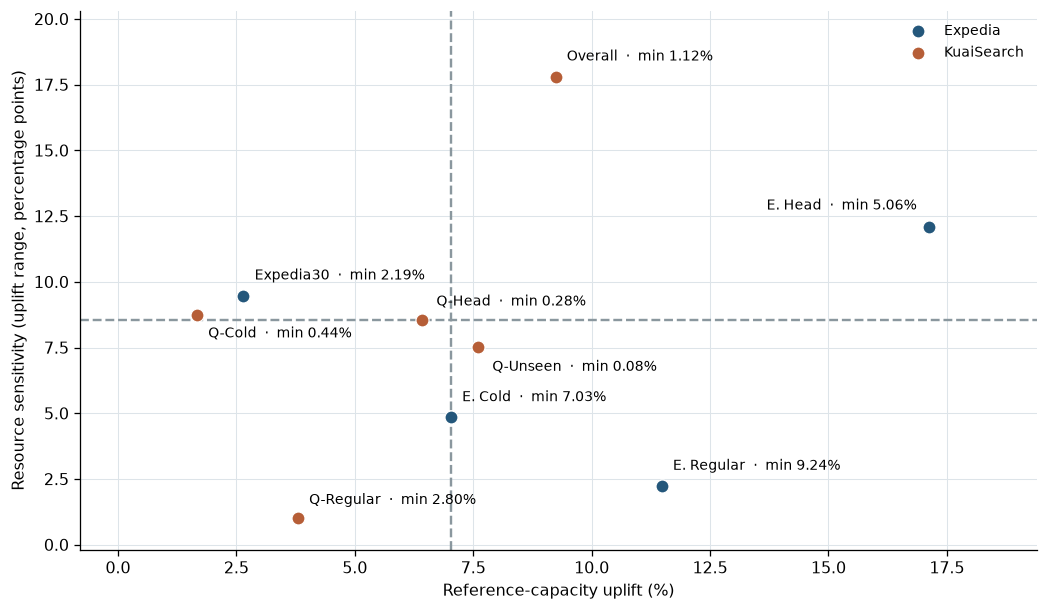

In [28]:
figure = render_figure("map", read_csv("figure-ec-02.csv"))
display(figure)
plt.close(figure)

### Figure EC.3. Minimum tested capacity required for a revenue target

[CSV](results/figure-ec-03.csv) · Derived from Tables EC.17 and EC.18

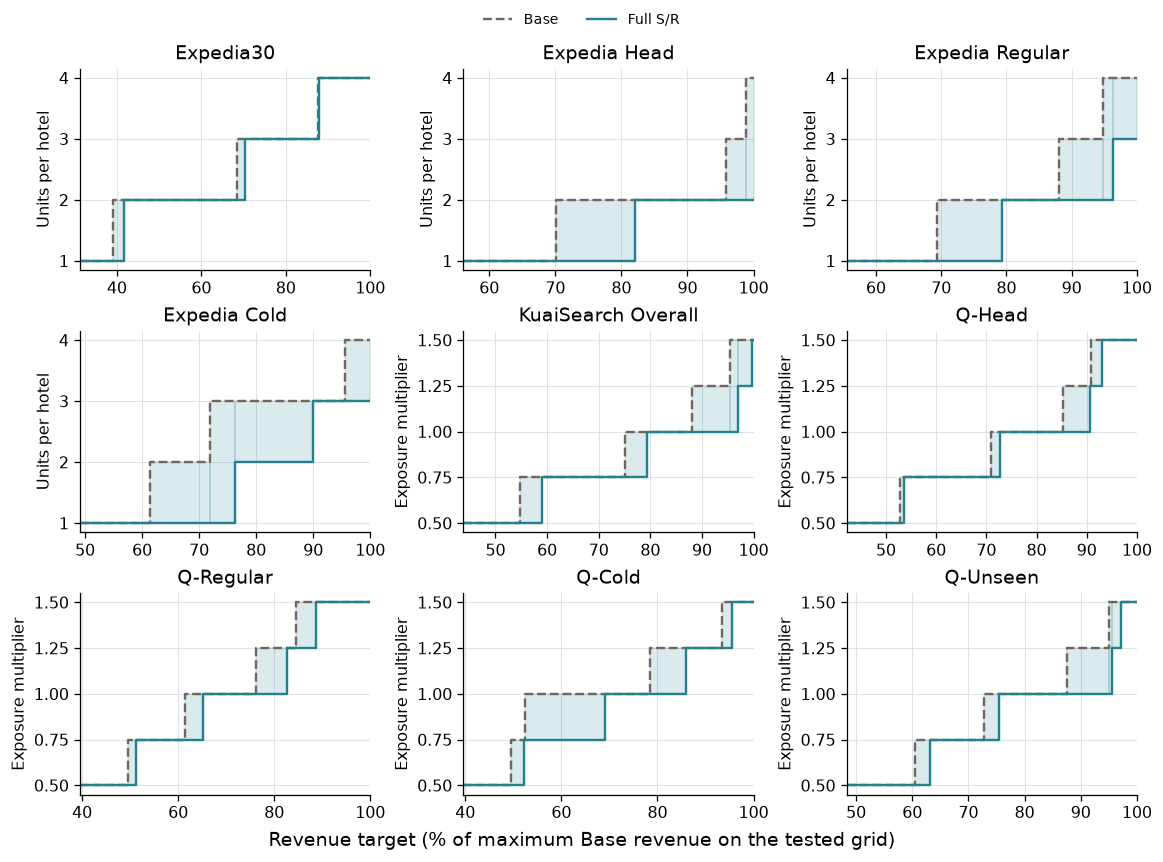

In [29]:
figure = render_figure("thresholds", read_csv("figure-ec-03.csv"))
display(figure)
plt.close(figure)

### Figure EC.4. Qwen S/R gain over the unaugmented A2C Transformer

[CSV](results/figure-ec-04.csv) · Derived from Table 3

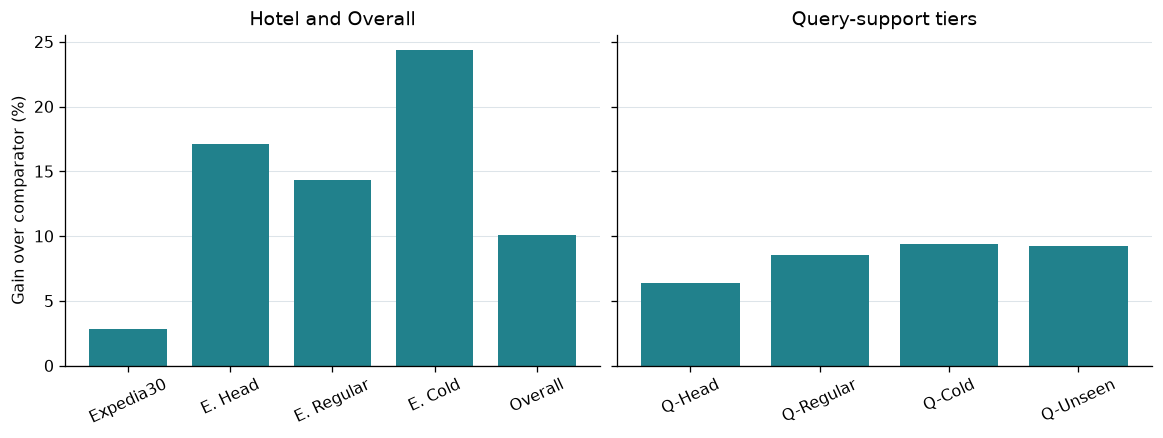

In [30]:
figure = render_figure("gains", read_csv("figure-ec-04.csv"))
display(figure)
plt.close(figure)

### Figure EC.5. Hotel market tier revenue and comparator-dependent Qwen S/R gain

[CSV](results/figure-ec-05.csv) · Derived from Table 3

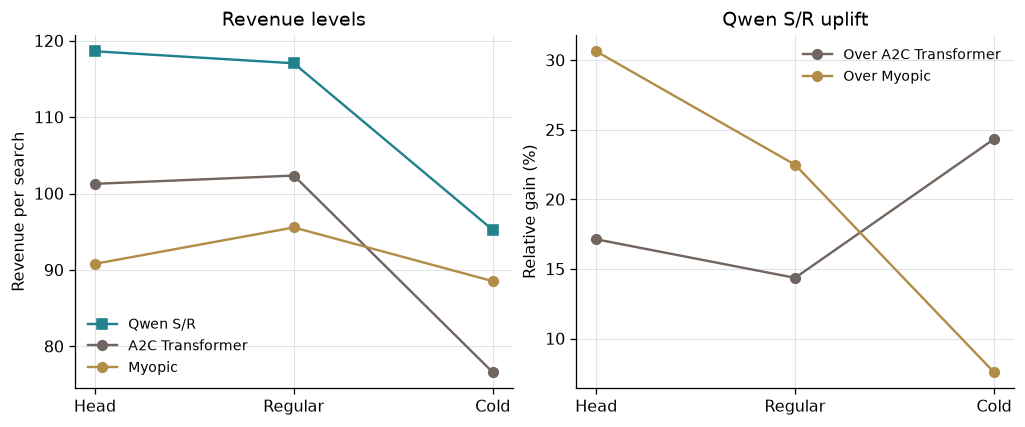

In [31]:
figure = render_figure("markets", read_csv("figure-ec-05.csv"))
display(figure)
plt.close(figure)

### Figure EC.6. Relative revenue gains for four LLM compilers

[CSV](results/figure-ec-06.csv) · Derived from Table 3

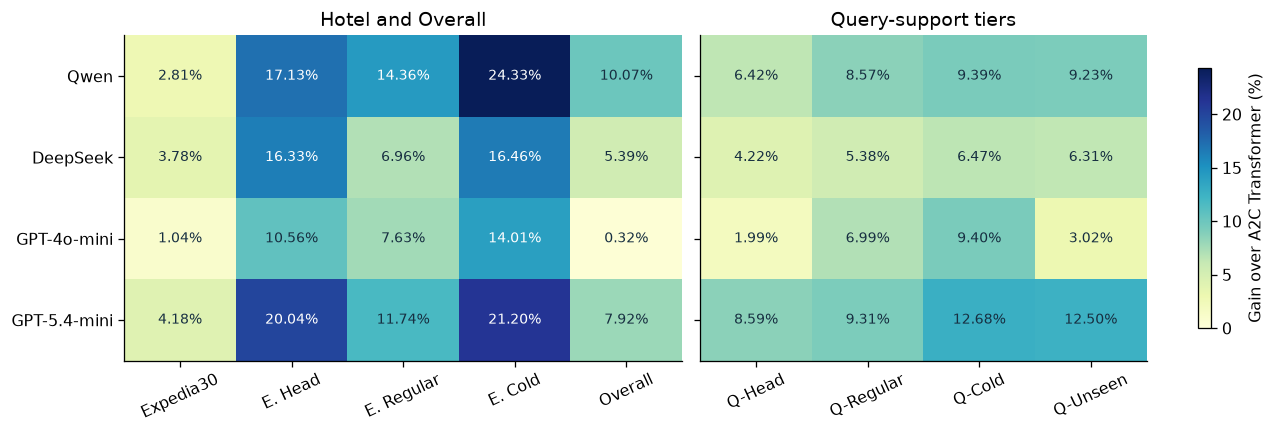

In [32]:
figure = render_figure("heatmap", read_csv("figure-ec-06.csv"))
display(figure)
plt.close(figure)

### Figure EC.7. Text encoder and compiled S/R gains versus A2C Transformer

[CSV](results/figure-ec-07.csv) · Derived from Table EC.14

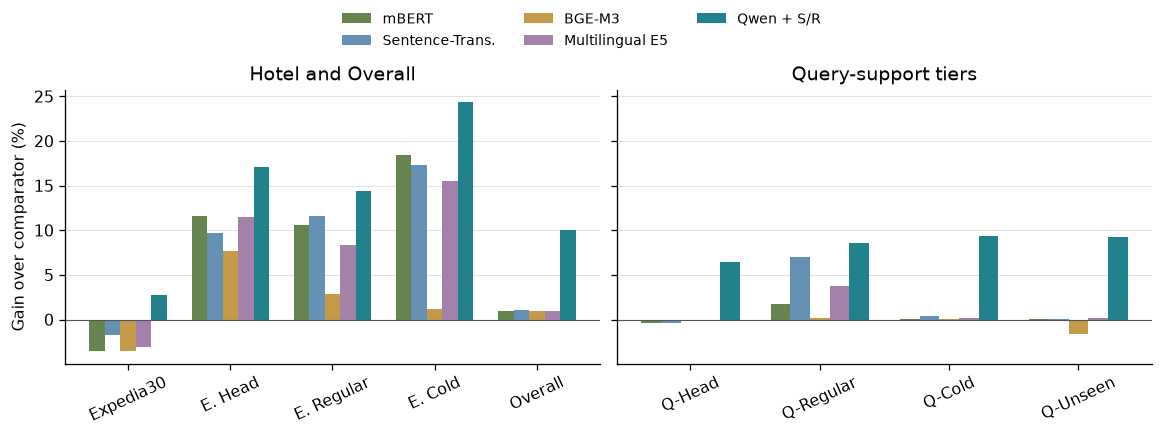

In [33]:
figure = render_figure("gains", read_csv("figure-ec-07.csv"))
display(figure)
plt.close(figure)

### Figure EC.8. Whole-slate PPO gain from adding Qwen S/R

[CSV](results/figure-ec-08.csv) · Derived from Table EC.10

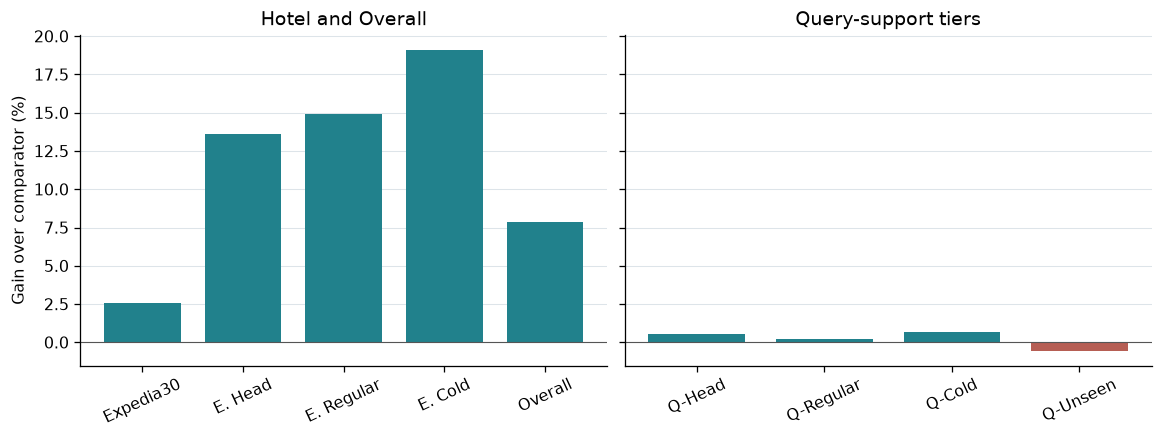

In [34]:
figure = render_figure("gains", read_csv("figure-ec-08.csv"))
display(figure)
plt.close(figure)

### Figure EC.9. Condition-specific hotel inventory response

[CSV](results/figure-ec-09.csv) · Table EC.17

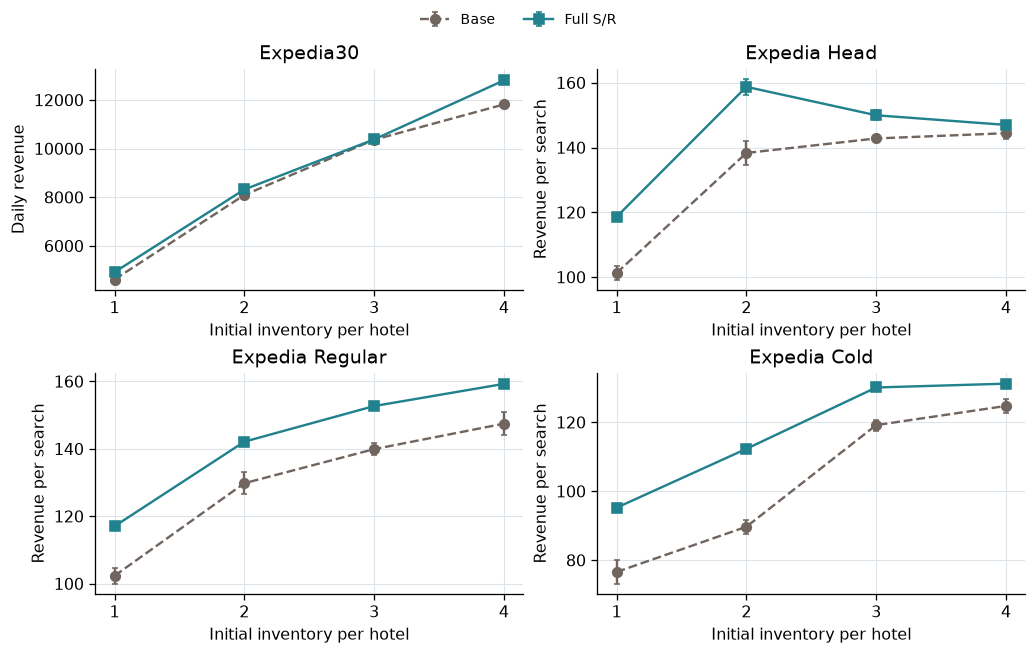

In [35]:
figure = render_figure("capacity", read_csv("figure-ec-09.csv"))
display(figure)
plt.close(figure)

### Figure EC.10. Condition-specific exposure response for query-support groups

[CSV](results/figure-ec-10.csv) · Table EC.18

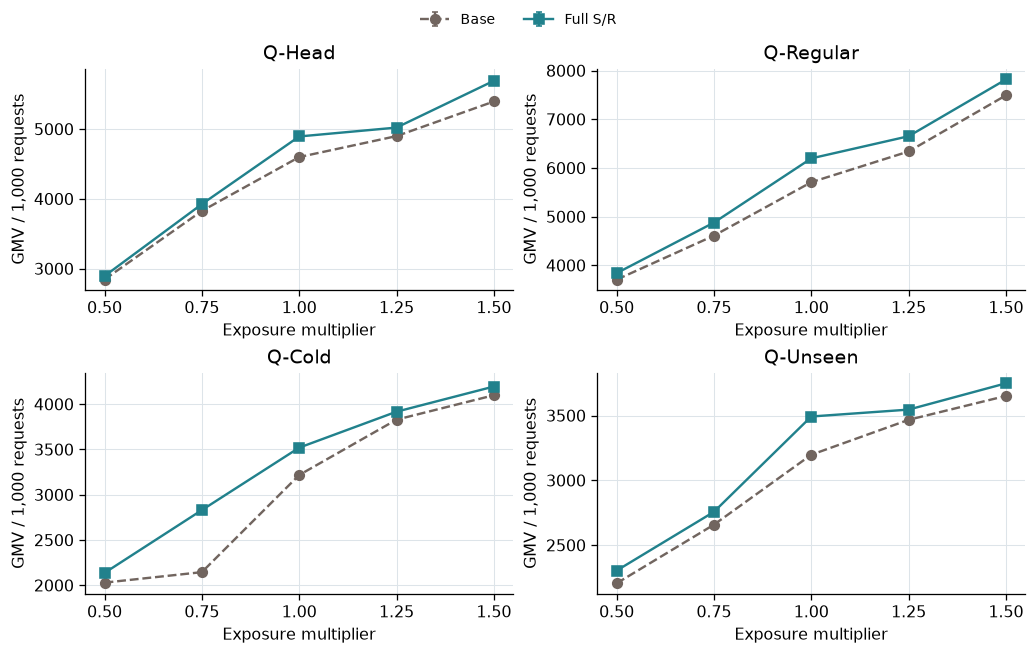

In [36]:
figure = render_figure("capacity", read_csv("figure-ec-10.csv"))
display(figure)
plt.close(figure)

## Appendix prompt parameter guide

### Box EC.1 parameter guide. Template parameter guide and heterogeneous-hotel instantiation

[CSV](results/box-ec-01-parameter-guide.csv) · Reported in manuscript

In [37]:
display(HTML(table_html(read_csv("box-ec-01-parameter-guide.csv"))))

Template field,Operational role,Heterogeneous-hotel instantiation
TASK_DESCRIPTION,Sequential decision setting,Dynamic hotel assortment across arriving searches
BUSINESS_OBJECTIVE,Held-out selection metric,Realized booking revenue per search ($J_{\mathrm{search}}$)
RESOURCE_RULES,Depletion law and cardinality,Initial stock $q$; deduct $1$ unit on booking; $|A_t| \le K$
INPUT_SCHEMA,Pre-decision state tensors,"Base globals $g_{t,1:8}^0$, item primitives, mask $V_t$"
FROZEN_STATISTICS,Training-fitted summaries $\eta$,"Bucketed demand $\widehat{D}_{tj}$, holding proxy $\widehat{h}_{tj}$, support $c_{tj}$"
TRANSITION_FIELDS,Training-time action inputs to $R$,Selected assortment mask $A_t$ and feasible mask $V_t$
S_SIGNATURE,Callable signature of $S$,"revise_state(global_base, candidate_base, available)"
S_OUTPUT_SCHEMA,Output shapes and data type,"Globals $[B,8]$, items $[B,M,4]$, float32"
GLOBAL_DIM / CANDIDATE_DIM,"Feature widths $(d_g, d_c)$","$d_g = 8$, $d_c = 4$"
R_SIGNATURE,Callable signature of $R$,"intrinsic_reward(global_f, candidate_f, available, selected)"
